<a href="https://colab.research.google.com/github/veera7705/LogicMojo-GenAI-AgenticAi-Oct26-Veera7705/blob/main/python_data_analysis_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Python Data Analysis Practice · Delivery Operations

An online retailer receives delivery updates from several carriers. A case can appear more than once as new updates arrive. The operations lead wants to know which cases are still active, which delays need attention, and what to include in a daily briefing.

Download [delivery_exceptions.csv](data/delivery_exceptions.csv) and run the setup cell. Run Jupyter from the notebook's folder so the CSV is under `data/`. In Colab, upload the CSV through the **Files** panel and update the path as shown in the setup comment. Use Python 3.11 or newer. If packages are missing, run `%pip install numpy pandas matplotlib seaborn requests` in a notebook cell.

Write your answer in the blank cell under each question. You can reuse your work on later questions. When a question refers to **cleaned cases**, use normalized text, valid delay values, and the latest update per case. An **active** case has status `open` or `in_progress`.

Refer to [Python Tools](01_python_tools.ipynb) and the [NumPy, pandas and chart sections](02_data_and_llms.ipynb) for class examples.

## Load the CSV

| Column | What it means |
| --- | --- |
| `case_id`, `order_id` | Delivery exception and associated order. A case can have multiple updates. |
| `opened_at`, `updated_at` | When the case was opened and when this update was recorded. |
| `region`, `city`, `carrier` | Where the order was going and who was handling it. |
| `issue_type` | Reason for the case, such as `delayed`, `damaged`, or `missing_parcel`. |
| `status`, `priority` | Current state at the time of the update and its assigned priority. |
| `delay_minutes` | Reported minutes past the delivery promise. Zero is valid. Blanks, labels such as `pending sync`, and negative values are unknown for analysis. |
| `customer_message` | Short example of what the customer reported. |

The setup loads the raw export so you can explore it in the questions below.

In [53]:
import pandas as pd

# In Colab, upload the CSV and change the path to "delivery_exceptions.csv".
raw_cases = pd.read_csv("/content/delivery_exceptions.csv")
display(raw_cases.head())

,case_id,order_id,opened_at,updated_at,region,city,carrier,issue_type,status,priority,delay_minutes,customer_message
0,7011,ORD-8411,2026-10-06T13:17,2026-10-06T18:57,north,Delhi,ParcelBridge,missing_parcel,resolved,high,150,The parcel has had no scan since it left the s...
1,7027,ORD-8427,2026-10-09T10:44,2026-10-09T14:19,east,Kolkata,ParcelBridge,damaged,resolved,low,25,"The outer box arrived crushed, and one item wa..."
2,7033,ORD-8433,2026-10-10T10:31,2026-10-10T18:17,west,Pune,MetroDispatch,address_issue,open,high,90,The driver called about the flat number. I hav...
3,7076,ORD-8476,2026-10-17T11:32,2026-10-17T13:52,south,Hyderabad,SwiftParcel,missing_parcel,in_progress,high,15,"Tracking says delivered, but I cannot find the..."
4,7060,ORD-8460,2026-10-14T14:04,2026-10-14T15:52,south,Hyderabad,RoutePost,damaged,resolved,normal,45,The seal was torn when I received the parcel.


## A. Explore the CSV

### 1. What came in the export?

Show the first five and last five rows, the shape, and the column names. Which column identifies an update's case? Which column tells you when that update happened?

In [54]:
print("Shape:", raw_cases.shape)

print("Columns:", raw_cases.columns.tolist())

print(raw_cases.head(5))

print(raw_cases.tail(5))

Shape: (88, 12)
Columns: ['case_id', 'order_id', 'opened_at', 'updated_at', 'region', 'city', 'carrier', 'issue_type', 'status', 'priority', 'delay_minutes', 'customer_message']
   case_id  order_id         opened_at        updated_at region       city  \
0     7011  ORD-8411  2026-10-06T13:17  2026-10-06T18:57  north      Delhi   
1     7027  ORD-8427  2026-10-09T10:44  2026-10-09T14:19   east    Kolkata   
2     7033  ORD-8433  2026-10-10T10:31  2026-10-10T18:17   west       Pune   
3     7076  ORD-8476  2026-10-17T11:32  2026-10-17T13:52  south  Hyderabad   
4     7060  ORD-8460  2026-10-14T14:04  2026-10-14T15:52  south  Hyderabad   

         carrier      issue_type       status priority delay_minutes  \
0   ParcelBridge  missing_parcel     resolved     high           150   
1   ParcelBridge         damaged     resolved      low            25   
2  MetroDispatch   address_issue         open     high            90   
3    SwiftParcel  missing_parcel  in_progress     high           

### 2. How many cases are there?

Count the raw rows and the distinct case IDs. List the IDs that appear more than once and count how many updates each has. What do the two counts tell you about how the export was produced?

In [55]:
total_rows = len(raw_cases)

unique_cases = raw_cases['case_id'].nunique()

duplicate_cases = raw_cases['case_id'].value_counts()
duplicate_cases = duplicate_cases[duplicate_cases > 1]

print("Total raw rows:", total_rows)
print("Distinct case IDs:", unique_cases)

print("\nDuplicate Case IDs:")
print(duplicate_cases)

Total raw rows: 88
Distinct case IDs: 80

Duplicate Case IDs:
case_id
7060    2
7037    2
7015    2
7049    2
7008    2
7080    2
7072    2
7024    2
Name: count, dtype: int64


### 3. Where is the data incomplete?

Count missing values in each raw column. Then inspect `delay_minutes` and list examples of missing, invalid, and valid values. Which of those categories do blanks, `pending sync`, negative numbers, and zero belong to?

In [56]:
raw_cases.isnull().sum()

,0
case_id,0
order_id,0
opened_at,0
updated_at,0
region,0
city,0
carrier,0
issue_type,0
status,0
priority,0


In [57]:
raw_cases['delay_minutes'].value_counts(dropna=False)

,count
delay_minutes,
150,9
45,9
480,7
0,7
25,6
120,6
15,5
180,5
240,5


In [58]:
delay = raw_cases['delay_minutes']

numeric_delay = pd.to_numeric(delay, errors='coerce')

missing = delay.isna()

invalid = delay.notna() & (
    numeric_delay.isna() | (numeric_delay < 0)
)

valid = delay.notna() & numeric_delay.notna() & (numeric_delay >= 0)

print("Missing:", missing.sum())
print("Invalid:", invalid.sum())
print("Valid:", valid.sum())

Missing: 1
Invalid: 8
Valid: 79


In [59]:
print("Missing values:")
print(delay[missing])

print("\nInvalid values:")
print(delay[invalid].unique())

print("\nValid values:")
print(delay[valid].unique())

Missing values:
33    NaN
Name: delay_minutes, dtype: object

Invalid values:
['pending sync' '-12' 'unknown' '-25']

Valid values:
['150' '25' '90' '15' '45' '480' '240' '360' '0' '120' '60' '165' '420'
 '180' '225' '205' '390' '145']


### 4. Which categories need standardization?

Show the distinct raw values of `status`, `region`, `carrier`, and `priority`. Find two labels that would be counted separately in a raw grouping even though they have the same meaning.

In [60]:
for col in ['status', 'region', 'carrier', 'priority']:
    print(f"\n{col}:")
    print(raw_cases[col].unique())


status:
['resolved' 'open' 'in_progress' 'In Progress' ' In Progress '
 'in-progress' 'RESOLVED' ' RESOLVED ' ' OPEN ']

region:
['north' 'east' 'west' 'south' ' NORTH ']

carrier:
['ParcelBridge' 'MetroDispatch' 'SwiftParcel' 'RoutePost'
 ' METRODISPATCH ']

priority:
['high' 'low' 'normal' 'urgent' ' HIGH ']


In [61]:
for col in ['status', 'region', 'carrier', 'priority']:
    print(f"\n{col}:")
    print(raw_cases[col].value_counts(dropna=False))


status:
status
resolved         34
open             27
in_progress      20
in-progress       2
In Progress       1
 In Progress      1
RESOLVED          1
 RESOLVED         1
 OPEN             1
Name: count, dtype: int64

region:
region
north      26
south      24
east       20
west       17
 NORTH      1
Name: count, dtype: int64

carrier:
carrier
RoutePost          25
SwiftParcel        24
ParcelBridge       20
MetroDispatch      18
 METRODISPATCH      1
Name: count, dtype: int64

priority:
priority
normal    48
high      20
low       11
urgent     8
 HIGH      1
Name: count, dtype: int64


### 5. What happened to case 7008?

Use `.loc` to display all updates for case 7008 with just the case ID, update time, status, and delay. Sort them by update time. Then use `.iloc` to select the last row of that result. Which status should a lookup tool return?

In [62]:
case_7008 = raw_cases.loc[
    raw_cases['case_id'] == 7008,
    ['case_id', 'updated_at', 'status', 'delay_minutes']
].sort_values('updated_at')

case_7008

,case_id,updated_at,status,delay_minutes
59,7008,2026-10-06T15:23,open,360
71,7008,2026-10-07T03:23,RESOLVED,390


In [63]:
case_7008.iloc[-1]

,71
case_id,7008
updated_at,2026-10-07T03:23
status,RESOLVED
delay_minutes,390


## B. Clean and prepare the data

### 6. Can you normalize the text labels?

Create a copy and trim spaces and lowercase the region, carrier, issue type, status, and priority columns. Use a mapping to turn both `in progress` and `in-progress` into `in_progress`. Compare the distinct status labels before and after cleaning.

In [64]:
clean_cases = raw_cases.copy()

cols = ['region', 'carrier', 'issue_type', 'status', 'priority']

for col in cols:
    clean_cases[col] = clean_cases[col].str.strip().str.lower()

clean_cases['status'] = clean_cases['status'].replace({
    'in progress': 'in_progress',
    'in-progress': 'in_progress'
})

print("Before cleaning:")
print(raw_cases['status'].unique())

print("\nAfter cleaning:")
print(clean_cases['status'].unique())

Before cleaning:
['resolved' 'open' 'in_progress' 'In Progress' ' In Progress '
 'in-progress' 'RESOLVED' ' RESOLVED ' ' OPEN ']

After cleaning:
['resolved' 'open' 'in_progress']


In [65]:
print("Before:", raw_cases['status'].nunique())
print("After:", clean_cases['status'].nunique())

Before: 9
After: 3


### 7. Can you turn a messy delay column into numbers?

Convert `delay_minutes` to numbers with pandas. Treat blanks, unparseable text, and negative values as missing. Keep zero as a valid measurement. How many measurements became missing? Inspect cases 7004, 7005, and 7006 to show the difference.

In [66]:
clean_cases['delay_minutes'] = pd.to_numeric(
    clean_cases['delay_minutes'],
    errors='coerce'
)

clean_cases.loc[
    clean_cases['delay_minutes'] < 0,
    'delay_minutes'
] = pd.NA

print("Missing measurements:", clean_cases['delay_minutes'].isna().sum())
print("Valid measurements:", clean_cases['delay_minutes'].notna().sum())

Missing measurements: 9
Valid measurements: 79


In [67]:
clean_cases.loc[
    clean_cases['case_id'].isin([7004, 7005, 7006]),
    ['case_id', 'delay_minutes']
]

,case_id,delay_minutes
45,7005,NaN
55,7004,0.0
84,7006,NaN


### 8. How much time passed before each update?

Parse `opened_at` and `updated_at` as datetimes. Create a column giving the minutes between opening and that update. Find the three updates with the largest elapsed time and explain what this measure tells you about a case.

In [68]:
clean_cases['opened_at'] = pd.to_datetime(clean_cases['opened_at'])
clean_cases['updated_at'] = pd.to_datetime(clean_cases['updated_at'])

clean_cases['elapsed_minutes'] = (
    clean_cases['updated_at'] - clean_cases['opened_at']
).dt.total_seconds() / 60

clean_cases.nlargest(
    3, 'elapsed_minutes'
)[['case_id', 'opened_at', 'updated_at', 'elapsed_minutes']]

,case_id,opened_at,updated_at,elapsed_minutes
76,7080,2026-10-18 09:33:00,2026-10-19 04:36:00,1143.0
71,7008,2026-10-06 09:11:00,2026-10-07 03:23:00,1092.0
29,7037,2026-10-11 08:08:00,2026-10-12 00:18:00,970.0


### 9. Which update should represent each case?

Sort by `updated_at` and keep the latest row for each `case_id`. The export is shuffled, so use the timestamp to decide which row to keep. Compare the status counts before and after deduplication.

In [69]:
latest_cases = clean_cases.sort_values('updated_at').drop_duplicates(
    subset='case_id',
    keep='last'
).reset_index(drop=True)

print("Before deduplication:")
print(clean_cases['status'].value_counts())

print("\nAfter deduplication:")
print(latest_cases['status'].value_counts())

Before deduplication:
status
resolved       36
open           28
in_progress    24
Name: count, dtype: int64

After deduplication:
status
resolved       29
open           27
in_progress    24
Name: count, dtype: int64


### 10. Can you make the cleaning reusable?

Package the cleaning and deduplication into `prepare_cases(raw_cases: pd.DataFrame) -> pd.DataFrame`. Return a new table and leave the input intact. Print a short summary of how many rows came in, how many unique cases remained, and how many of those cases had unknown delays.

In [70]:
def prepare_cases(raw_cases: pd.DataFrame) -> pd.DataFrame:
    cases = raw_cases.copy()

    cols = ['region', 'carrier', 'issue_type', 'status', 'priority']

    for col in cols:
        cases[col] = cases[col].str.strip().str.lower()

    cases['status'] = cases['status'].replace({
        'in progress': 'in_progress',
        'in-progress': 'in_progress'
    })

    cases['delay_minutes'] = pd.to_numeric(
        cases['delay_minutes'],
        errors='coerce'
    )

    cases.loc[cases['delay_minutes'] < 0, 'delay_minutes'] = pd.NA

    cases['opened_at'] = pd.to_datetime(
        cases['opened_at'], errors='coerce'
    )

    cases['updated_at'] = pd.to_datetime(
        cases['updated_at'], errors='coerce'
    )

    cases['elapsed_minutes'] = (
        cases['updated_at'] - cases['opened_at']
    ).dt.total_seconds() / 60

    cases = cases.sort_values('updated_at').drop_duplicates(
        subset='case_id',
        keep='last'
    ).reset_index(drop=True)

    print("Rows received:", len(raw_cases))
    print("Unique cases remaining:", len(cases))
    print("Cases with unknown delays:", cases['delay_minutes'].isna().sum())

    return cases


latest_cases = prepare_cases(raw_cases)

Rows received: 88
Unique cases remaining: 80
Cases with unknown delays: 9


## C. Practise Python functions for agent tools

### 11. Can you validate a case ID from a request?

Write `parse_case_id(value: object) -> int`. Accept positive integers and digit strings after trimming spaces. Raise `ValueError` for other values, including booleans. Try it with `7001`, `" 7001 "`, `"ORD-8401"`, and `True`.

In [71]:
def parse_case_id(value: object) -> int:
    if isinstance(value, bool):
        raise ValueError("Invalid case ID")

    if isinstance(value, int):
        if value > 0:
            return value
        raise ValueError("Case ID must be positive")

    if isinstance(value, str):
        value = value.strip()

        if value.isdigit() and int(value) > 0:
            return int(value)

    raise ValueError("Invalid case ID")


test_values = [7001, " 7001 ", "ORD-8401", True]

for value in test_values:
    try:
        print(value, "->", parse_case_id(value))
    except ValueError as e:
        print(value, "-> ValueError:", e)

7001 -> 7001
 7001  -> 7001
ORD-8401 -> ValueError: Invalid case ID
True -> ValueError: Invalid case ID


### 12. Can you look up the latest status?

Convert the cleaned table to a list of dictionaries. Write a lookup function that accepts a case ID and returns a dictionary with the case ID, status, carrier, and issue type. Return an error dictionary if the ID is missing from the dataset, and try a known ID and an absent one.

In [72]:
case_records = latest_cases.to_dict(orient='records')


def lookup_case(case_id: object) -> dict:
    try:
        case_id = parse_case_id(case_id)
    except ValueError:
        return {"error": "Invalid case ID"}

    for case in case_records:
        if case['case_id'] == case_id:
            return {
                "case_id": case['case_id'],
                "status": case['status'],
                "carrier": case['carrier'],
                "issue_type": case['issue_type']
            }

    return {"error": "Case ID not found"}


print(lookup_case(7001))
print(lookup_case(9999))

{'case_id': 7001, 'status': 'open', 'carrier': 'metrodispatch', 'issue_type': 'delayed'}
{'error': 'Case ID not found'}


### 13. Which cases should the operations team review first?

Write a function that accepts the records, a region, and a delay threshold. Return active cases in that region with a known delay at or above the threshold. Use a lambda to order them by longest delay first, with smaller case IDs first when delays tie. Compare the North region at 120 and 240 minutes.

In [73]:
def review_cases(records, region, threshold):
    filtered_cases = [
        case for case in records
        if case['region'] == region.strip().lower()
        and case['status'] in ['open', 'in_progress']
        and pd.notna(case['delay_minutes'])
        and case['delay_minutes'] >= threshold
    ]

    return sorted(
        filtered_cases,
        key=lambda x: (-x['delay_minutes'], x['case_id'])
    )


north_120 = review_cases(case_records, 'North', 120)
north_240 = review_cases(case_records, 'North', 240)

print("North region - 120 minutes:")
for case in north_120:
    print(case['case_id'], case['status'], case['delay_minutes'])

print("\nNorth region - 240 minutes:")
for case in north_240:
    print(case['case_id'], case['status'], case['delay_minutes'])

North region - 120 minutes:
7016 open 480.0
7035 open 360.0
7002 in_progress 240.0
7064 open 240.0
7021 open 150.0
7001 open 120.0
7010 open 120.0

North region - 240 minutes:
7016 open 480.0
7035 open 360.0
7002 in_progress 240.0
7064 open 240.0


### 14. How can one run avoid reviewing a case twice?

Build a `DeliveryRun` class with a set on each instance. Give it methods to mark an ID as seen, check whether it was seen, and count distinct IDs. Create two instances, mark an ID twice in the first, and show what each instance remembers.

In [74]:
class DeliveryRun:
    def __init__(self):
        self.seen_cases = set()

    def mark_seen(self, case_id):
        self.seen_cases.add(case_id)

    def has_seen(self, case_id):
        return case_id in self.seen_cases

    def count_distinct(self):
        return len(self.seen_cases)


run1 = DeliveryRun()
run2 = DeliveryRun()

run1.mark_seen(7001)
run1.mark_seen(7001)

print("Run 1 remembers:", run1.seen_cases)
print("Run 1 has seen 7001:", run1.has_seen(7001))
print("Run 1 distinct count:", run1.count_distinct())

print("\nRun 2 remembers:", run2.seen_cases)
print("Run 2 has seen 7001:", run2.has_seen(7001))
print("Run 2 distinct count:", run2.count_distinct())

Run 1 remembers: {7001}
Run 1 has seen 7001: True
Run 1 distinct count: 1

Run 2 remembers: set()
Run 2 has seen 7001: False
Run 2 distinct count: 0


### 15. Can you turn case records into short descriptions?

Write a named function that accepts one case and returns a line such as `Case 7008 | north | resolved`. Apply it to a list of records using Python's built-in `map()`. Use `functools.reduce()` to total the known delays for active cases and compare the result with `sum()`.

In [75]:
from functools import reduce

def describe_case(case):
    return f"Case {case['case_id']} | {case['region']} | {case['status']}"


descriptions = list(map(describe_case, case_records))

for description in descriptions:
    print(description)


active_cases = [
    case for case in case_records
    if case['status'] in ['open', 'in_progress']
    and pd.notna(case['delay_minutes'])
]


total_delay_reduce = reduce(
    lambda total, case: total + case['delay_minutes'],
    active_cases,
    0
)

total_delay_sum = sum(
    case['delay_minutes'] for case in active_cases
)

print("\nTotal delay using reduce():", total_delay_reduce)
print("Total delay using sum():", total_delay_sum)

Case 7001 | north | open
Case 7003 | north | open
Case 7005 | east | open
Case 7002 | north | in_progress
Case 7006 | west | in_progress
Case 7004 | south | open
Case 7007 | south | open
Case 7009 | east | in_progress
Case 7010 | north | open
Case 7011 | north | resolved
Case 7012 | north | resolved
Case 7008 | north | resolved
Case 7013 | south | in_progress
Case 7014 | north | resolved
Case 7018 | west | in_progress
Case 7016 | north | open
Case 7017 | south | resolved
Case 7015 | east | in_progress
Case 7019 | east | open
Case 7020 | south | resolved
Case 7021 | north | open
Case 7022 | north | in_progress
Case 7023 | west | in_progress
Case 7024 | west | resolved
Case 7025 | east | in_progress
Case 7026 | north | open
Case 7028 | east | in_progress
Case 7027 | east | resolved
Case 7029 | west | in_progress
Case 7030 | east | in_progress
Case 7031 | south | in_progress
Case 7032 | south | open
Case 7034 | north | resolved
Case 7036 | east | resolved
Case 7035 | north | open
Case 703

## D. Analyze the backlog with NumPy and pandas

### 16. How many delays meet each threshold?

Build a NumPy array of known delays from active cases. Use boolean masks to count the delays at or above 60, 120, and 240 minutes. Also report the minimum, median, and maximum. How many active cases were excluded because their delays were unknown?

In [76]:
import numpy as np

active_cases = latest_cases[
    latest_cases['status'].isin(['open', 'in_progress'])
]

known_delays = active_cases['delay_minutes'].dropna().to_numpy()

print("Delays >= 60 minutes:", np.sum(known_delays >= 60))
print("Delays >= 120 minutes:", np.sum(known_delays >= 120))
print("Delays >= 240 minutes:", np.sum(known_delays >= 240))

print("\nMinimum:", np.min(known_delays))
print("Median:", np.median(known_delays))
print("Maximum:", np.max(known_delays))

unknown_delays = active_cases['delay_minutes'].isna().sum()

print("\nActive cases excluded due to unknown delays:", unknown_delays)

Delays >= 60 minutes: 28
Delays >= 120 minutes: 22
Delays >= 240 minutes: 7

Minimum: 0.0
Median: 120.0
Maximum: 480.0

Active cases excluded due to unknown delays: 8


### 17. What happens when you combine two conditions?

Use `.loc` to find high or urgent active cases with a known delay of at least 120 minutes. Show only the case ID, region, carrier, priority, and delay. Sort the result and use `.iloc` to display the first three matching rows.

In [77]:
filtered_cases = latest_cases.loc[
    (latest_cases['status'].isin(['open', 'in_progress'])) &
    (latest_cases['priority'].isin(['high', 'urgent'])) &
    (latest_cases['delay_minutes'].notna()) &
    (latest_cases['delay_minutes'] >= 120),
    ['case_id', 'region', 'carrier', 'priority', 'delay_minutes']
]

filtered_cases = filtered_cases.sort_values(
    by=['delay_minutes', 'case_id'],
    ascending=[False, True]
).reset_index(drop=True)

print("Total matching cases:", len(filtered_cases))

filtered_cases.iloc[:3]

Total matching cases: 10


,case_id,region,carrier,priority,delay_minutes
0,7046,east,parcelbridge,high,480.0
1,7037,west,routepost,urgent,420.0
2,7002,north,routepost,urgent,240.0


### 18. Which carriers have the most active cases?

Group active cases by carrier. For each carrier, show the number of active cases, the number with a known delay, and the average known delay. Why might `.size()` and `.count()` give different numbers?

In [78]:
active_cases = latest_cases[
    latest_cases['status'].isin(['open', 'in_progress'])
]

carrier_summary = active_cases.groupby('carrier').agg(
    active_cases=('case_id', 'size'),
    known_delays=('delay_minutes', 'count'),
    average_delay=('delay_minutes', 'mean')
).reset_index()

carrier_summary = carrier_summary.sort_values(
    by='active_cases',
    ascending=False
)

print(carrier_summary)

         carrier  active_cases  known_delays  average_delay
0  metrodispatch            15            15           97.0
3    swiftparcel            13            10          133.0
2      routepost            12            10          178.5
1   parcelbridge            11             8          125.0


### 19. Can you assign a label to each known delay?

Use `Series.map()` with a dictionary to give each priority a readable label. Then use `Series.apply()` with a named function to label delays as `unknown`, `under 120 minutes`, or `120 minutes or more`. Show the counts for each delay label among active cases.

In [79]:
priority_labels = {
    'high': 'High Priority',
    'urgent': 'Urgent Priority',
    'normal': 'Normal Priority',
    'low': 'Low Priority'
}

active_cases['priority_label'] = active_cases['priority'].map(priority_labels)


def label_delay(delay):
    if pd.isna(delay):
        return 'unknown'
    elif delay < 120:
        return 'under 120 minutes'
    else:
        return '120 minutes or more'


active_cases['delay_label'] = active_cases['delay_minutes'].apply(label_delay)

print(active_cases['delay_label'].value_counts())

delay_label
120 minutes or more    22
under 120 minutes      21
unknown                 8
Name: count, dtype: int64


/tmp/ipykernel_578/3839119442.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  active_cases['priority_label'] = active_cases['priority'].map(priority_labels)
/tmp/ipykernel_578/3839119442.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  active_cases['delay_label'] = active_cases['delay_minutes'].apply(label_delay)


### 20. Which region and carrier combinations need attention?

Build a grouped table by region and carrier for active cases. Show the active count and the number at or above 120 minutes. Calculate the percentage meeting the threshold **among known delays** and use a missing result when a group has no known delays. Which combinations look different when you compare counts with percentages?

In [80]:
active_cases = latest_cases[
    latest_cases['status'].isin(['open', 'in_progress'])
]

region_carrier_summary = active_cases.groupby(
    ['region', 'carrier']
).agg(
    active_count=('case_id', 'size'),
    known_delays=('delay_minutes', 'count'),
    delays_120_plus=('delay_minutes', lambda x: (x >= 120).sum())
).reset_index()

region_carrier_summary['threshold_percentage'] = (
    region_carrier_summary['delays_120_plus']
    / region_carrier_summary['known_delays'] * 100
)

region_carrier_summary.loc[
    region_carrier_summary['known_delays'] == 0,
    'threshold_percentage'
] = np.nan

region_carrier_summary = region_carrier_summary.sort_values(
    by='threshold_percentage',
    ascending=False,
    na_position='last'
)

print(region_carrier_summary)

   region        carrier  active_count  known_delays  delays_120_plus  \
3    east    swiftparcel             3             3                3   
6   north      routepost             3             3                3   
10  south      routepost             3             2                2   
13   west   parcelbridge             1             1                1   
0    east  metrodispatch             3             3                2   
2    east      routepost             2             2                1   
1    east   parcelbridge             5             4                2   
5   north   parcelbridge             4             2                1   
4   north  metrodispatch             4             4                2   
7   north    swiftparcel             3             2                1   
12   west  metrodispatch             6             6                2   
14   west      routepost             4             3                1   
11  south    swiftparcel             7             

## E. Choose and explain a chart

### 21. Which carrier has the most active cases?

Make a Seaborn count plot using active cases by carrier. Add labels above the bars and compare them with your grouped counts. Give the chart a title and label both axes.

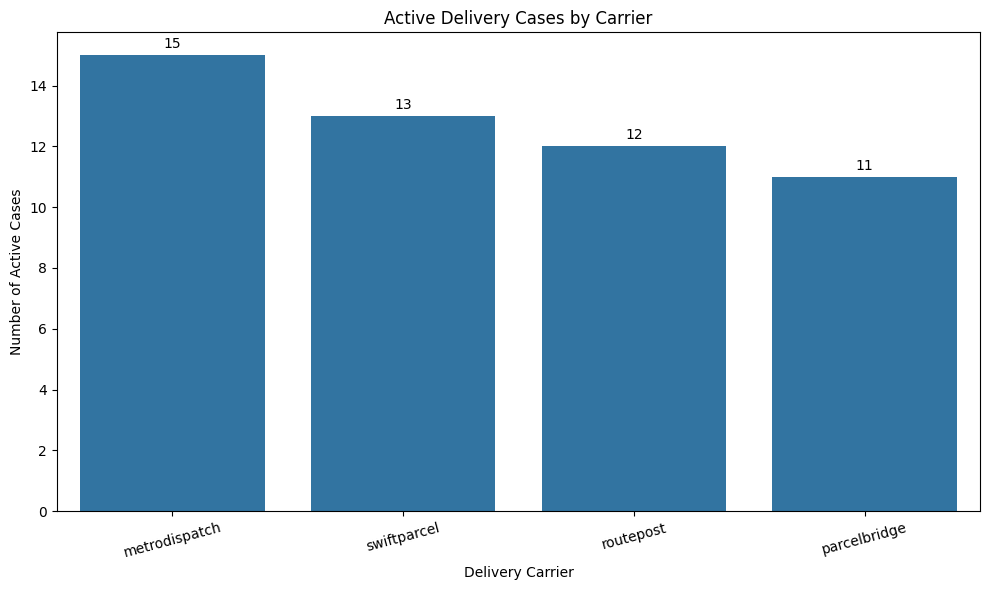

carrier
metrodispatch    15
swiftparcel      13
routepost        12
parcelbridge     11
dtype: int64


In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=active_cases,
    x='carrier',
    order=active_cases['carrier'].value_counts().index
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Active Delivery Cases by Carrier')
plt.xlabel('Delivery Carrier')
plt.ylabel('Number of Active Cases')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

carrier_counts = active_cases.groupby('carrier').size().sort_values(ascending=False)

print(carrier_counts)

### 22. How are known delays distributed?

Plot a histogram of known delays for active cases. Draw a line at 120 minutes, then compare the chart with the exact count from a mask. How could changing the histogram bins change what you notice?

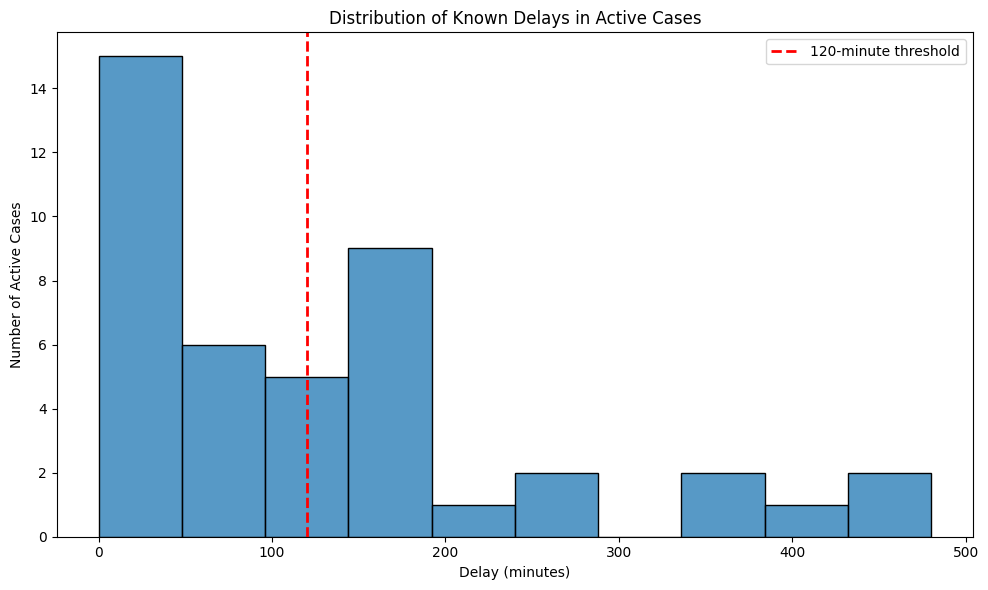

Known delays: 43
Delays >= 120 minutes: 22
Delays < 120 minutes: 21


In [82]:
import matplotlib.pyplot as plt
import seaborn as sns

known_delays = active_cases['delay_minutes'].dropna()

plt.figure(figsize=(10, 6))

ax = sns.histplot(
    known_delays,
    bins=10,
    kde=False
)

plt.axvline(120, color='red', linestyle='--', linewidth=2, label='120-minute threshold')

plt.title('Distribution of Known Delays in Active Cases')
plt.xlabel('Delay (minutes)')
plt.ylabel('Number of Active Cases')
plt.legend()
plt.tight_layout()
plt.show()

delay_mask = active_cases['delay_minutes'] >= 120

count_120_or_more = delay_mask.sum()
count_below_120 = (active_cases['delay_minutes'].notna() & (active_cases['delay_minutes'] < 120)).sum()

print("Known delays:", known_delays.count())
print("Delays >= 120 minutes:", count_120_or_more)
print("Delays < 120 minutes:", count_below_120)

### 23. Which regions have a wider spread of delays?

Make a Seaborn box plot of known active delays by region. Compare medians and spread. Choose one region with a point beyond a whisker and look up the case or cases that may explain it.

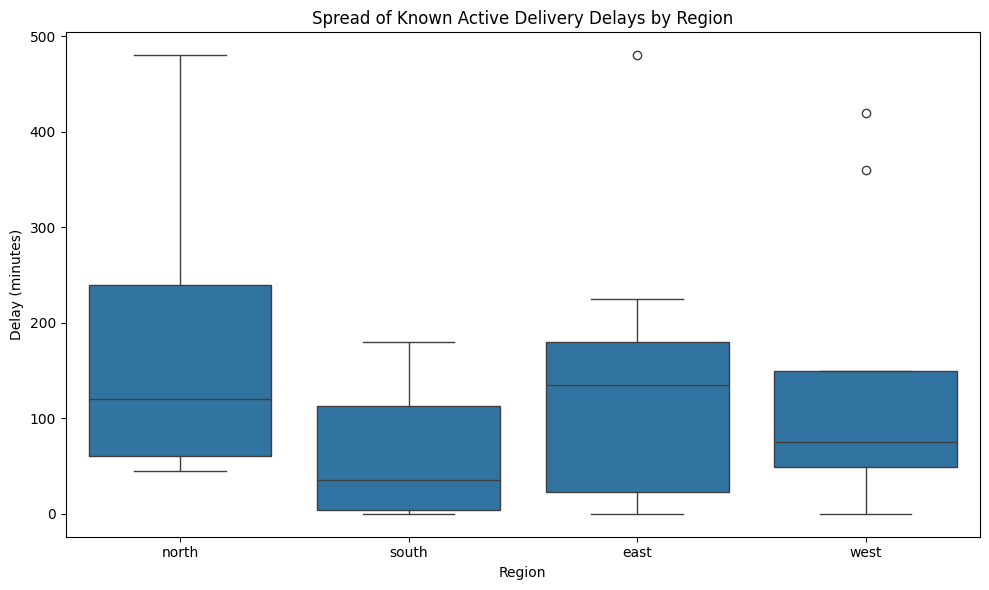

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

known_active = active_cases.dropna(subset=['delay_minutes'])

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=known_active,
    x='region',
    y='delay_minutes'
)

plt.title('Spread of Known Active Delivery Delays by Region')
plt.xlabel('Region')
plt.ylabel('Delay (minutes)')
plt.tight_layout()
plt.show()

In [84]:
region_summary = known_active.groupby('region')['delay_minutes'].agg(
    count='count',
    median='median',
    mean='mean',
    minimum='min',
    maximum='max',
    standard_deviation='std'
)

print(region_summary)

        count  median        mean  minimum  maximum  standard_deviation
region                                                                 
east       12   135.0  139.583333      0.0    480.0          131.985852
north      11   120.0  174.545455     45.0    480.0          142.345610
south      10    35.0   62.500000      0.0    180.0           67.669540
west       10    75.0  135.000000      0.0    420.0          143.874946


In [85]:
east_outlier = known_active[
    (known_active['region'] == 'east') &
    (known_active['delay_minutes'] > 416.25)
]

print(east_outlier[
    ['case_id', 'order_id', 'city', 'carrier',
     'issue_type', 'priority', 'status', 'delay_minutes']
])

    case_id  order_id         city       carrier issue_type priority status  \
43     7046  ORD-8446  Bhubaneswar  parcelbridge    delayed     high   open   

    delay_minutes  
43          480.0  


### 24. How did new exceptions change over time?

Count unique cases by the calendar day on which they opened. Plot the counts in date order as a line chart. Identify the busiest day. Explain why cases opened on a day and cases still active on that day are different measures.

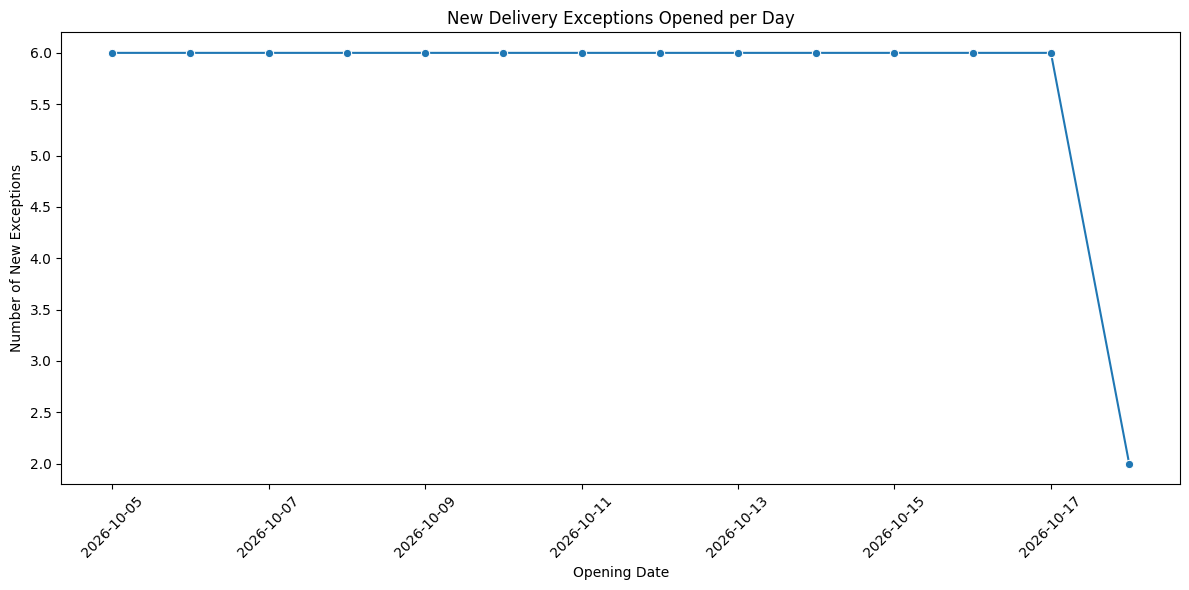

Daily exception counts:
   opened_day  new_exceptions
0  2026-10-05               6
1  2026-10-06               6
2  2026-10-07               6
3  2026-10-08               6
4  2026-10-09               6
5  2026-10-10               6
6  2026-10-11               6
7  2026-10-12               6
8  2026-10-13               6
9  2026-10-14               6
10 2026-10-15               6
11 2026-10-16               6
12 2026-10-17               6
13 2026-10-18               2

Busiest day(s):
   opened_day  new_exceptions
0  2026-10-05               6
1  2026-10-06               6
2  2026-10-07               6
3  2026-10-08               6
4  2026-10-09               6
5  2026-10-10               6
6  2026-10-11               6
7  2026-10-12               6
8  2026-10-13               6
9  2026-10-14               6
10 2026-10-15               6
11 2026-10-16               6
12 2026-10-17               6


In [86]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

daily_exceptions = (
    raw_cases.assign(
        opened_day=pd.to_datetime(raw_cases['opened_at']).dt.floor('D')
    )
    .groupby('opened_day')['case_id']
    .nunique()
    .sort_index()
    .reset_index(name='new_exceptions')
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=daily_exceptions,
    x='opened_day',
    y='new_exceptions',
    marker='o'
)

plt.title('New Delivery Exceptions Opened per Day')
plt.xlabel('Opening Date')
plt.ylabel('Number of New Exceptions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

busiest_days = daily_exceptions[
    daily_exceptions['new_exceptions'] == daily_exceptions['new_exceptions'].max()
]

print("Daily exception counts:")
print(daily_exceptions)

print("\nBusiest day(s):")
print(busiest_days)

### 25. Do longer recorded delays come with longer update times?

On the cleaned table, make a scatter plot of delay minutes against minutes from opening to the latest update. Use region as the color and exclude unknown delays. Describe one pattern or exception, and name another factor you would want to check before drawing a conclusion.

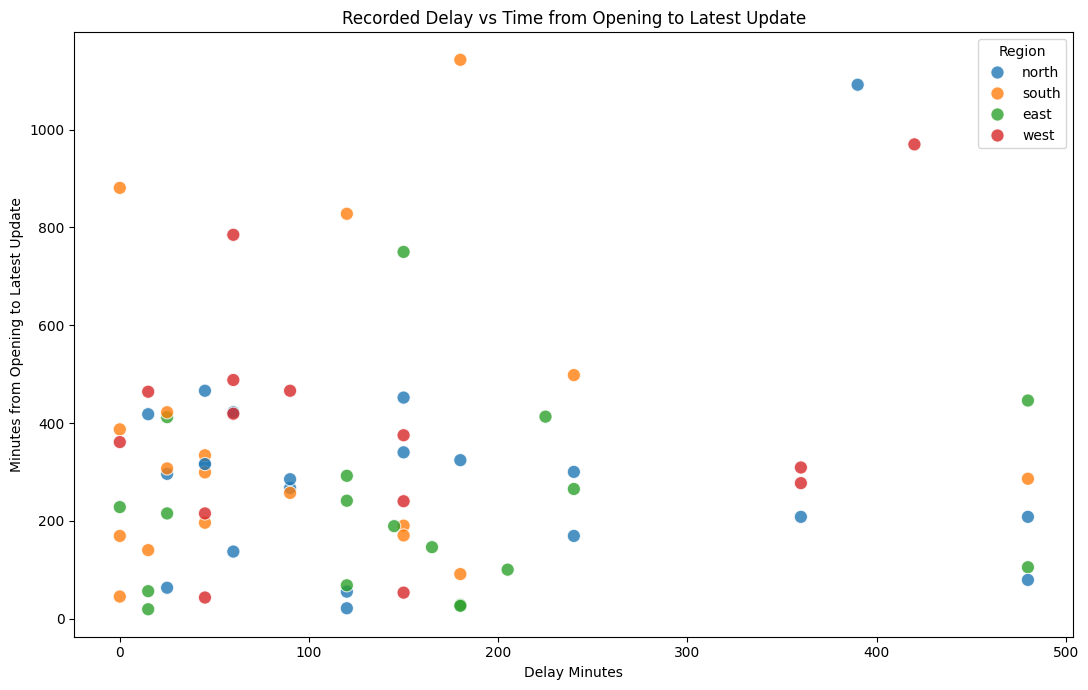

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = latest_cases.dropna(
    subset=['delay_minutes', 'elapsed_minutes', 'region']
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_data,
    x='delay_minutes',
    y='elapsed_minutes',
    hue='region',
    s=90,
    alpha=0.8
)

plt.title('Recorded Delay vs Time from Opening to Latest Update')
plt.xlabel('Delay Minutes')
plt.ylabel('Minutes from Opening to Latest Update')
plt.legend(title='Region')
plt.tight_layout()
plt.show()


In [88]:
correlation = plot_data['delay_minutes'].corr(
    plot_data['elapsed_minutes']
)

print("Correlation:", correlation)

Correlation: 0.09271199986043191


In [89]:
print(
    plot_data.sort_values(
        'elapsed_minutes',
        ascending=False
    )[
        ['case_id', 'region', 'carrier', 'status',
         'delay_minutes', 'elapsed_minutes']
    ].head(5)
)

    case_id region        carrier       status  delay_minutes  elapsed_minutes
79     7080  south   parcelbridge     resolved          180.0           1143.0
11     7008  north  metrodispatch     resolved          390.0           1092.0
41     7037   west      routepost         open          420.0            970.0
53     7049  south   parcelbridge     resolved            0.0            881.0
59     7060  south      routepost  in_progress          120.0            828.0


## F. Build Python tools and reports

### 26. Can your program exchange a tool request as JSON?

Start with `{"tool": "get_case_status", "case_id": "7008"}` as JSON text. Parse it, call the lookup tool, and convert the returned dictionary back to JSON text. Decide what error the application should return for malformed JSON, an unsupported tool, and an absent case. Demonstrate one request for each outcome.

In [90]:
import json

def process_tool_request(request_text):
    try:
        request = json.loads(request_text)
    except json.JSONDecodeError:
        return json.dumps({
            "error": "Malformed JSON request"
        })

    if not isinstance(request, dict):
        return json.dumps({
            "error": "Request must be a JSON object"
        })

    if request.get("tool") != "get_case_status":
        return json.dumps({
            "error": "Unsupported tool"
        })

    result = lookup_case(request.get("case_id"))

    return json.dumps(result, default=str)


request = '{"tool": "get_case_status", "case_id": "7008"}'
response = process_tool_request(request)

print(response)

{"case_id": 7008, "status": "resolved", "carrier": "metrodispatch", "issue_type": "delayed"}


In [91]:
print(process_tool_request('{"tool": "get_case_status",'))
print(process_tool_request('{"tool": "delete_case", "case_id": "7008"}'))
print(process_tool_request('{"tool": "get_case_status", "case_id": "999999"}'))

{"error": "Malformed JSON request"}
{"error": "Unsupported tool"}
{"error": "Case ID not found"}


### 27. Can you wrap an HTTP request in a Python function?

Use the class practice endpoint at `https://jsonplaceholder.typicode.com/todos/1`. Write a function that accepts a task ID, sends a GET request with a timeout, checks the response status, and returns a dictionary with the ID, title, and completion state. Decide how to return a useful error if the request cannot complete. You can use a sample response dictionary when practising offline.

In [92]:
import requests

def get_todo(task_id):
    url = f"https://jsonplaceholder.typicode.com/todos/{task_id}"

    try:
        response = requests.get(url, timeout=10)
        response.raise_for_status()

        data = response.json()

        return {
            "id": int(data["id"]),
            "title": str(data["title"]),
            "completed": bool(data["completed"])
        }

    except requests.exceptions.Timeout:
        return {"error": "Request timed out"}

    except requests.exceptions.RequestException as e:
        return {"error": f"Request failed: {str(e)}"}

    except (ValueError, KeyError):
        return {"error": "Invalid response data"}


todo = get_todo(1)
print(todo)

{'id': 1, 'title': 'delectus aut autem', 'completed': False}


### 28. Can you save and reload a daily report?

Build a dictionary with the total active cases, unknown delays, counts by carrier, and number of active cases delayed at least 120 minutes. Save it as `practice_delivery_report.json` using UTF-8. Reload it and show that the values match. Convert any pandas or NumPy values to JSON-compatible Python types where needed.

In [93]:
import json

daily_report = {
    "total_active_cases": int(len(active_cases)),
    "unknown_delays": int(active_cases['delay_minutes'].isna().sum()),
    "counts_by_carrier": {
        str(k): int(v)
        for k, v in active_cases['carrier'].value_counts().items()
    },
    "delays_at_least_120": int(
        (active_cases['delay_minutes'] >= 120).sum()
    )
}

with open("practice_delivery_report.json", "w", encoding="utf-8") as file:
    json.dump(daily_report, file, indent=4, ensure_ascii=False)

with open("practice_delivery_report.json", "r", encoding="utf-8") as file:
    loaded_report = json.load(file)

print("Original report:")
print(daily_report)

print("\nReloaded report:")
print(loaded_report)

print("\nValues match:", daily_report == loaded_report)

Original report:
{'total_active_cases': 51, 'unknown_delays': 8, 'counts_by_carrier': {'metrodispatch': 15, 'swiftparcel': 13, 'routepost': 12, 'parcelbridge': 11}, 'delays_at_least_120': 22}

Reloaded report:
{'total_active_cases': 51, 'unknown_delays': 8, 'counts_by_carrier': {'metrodispatch': 15, 'swiftparcel': 13, 'routepost': 12, 'parcelbridge': 11}, 'delays_at_least_120': 22}

Values match: True


### 29. Can your tool validate a delay search request?

Start with `{"tool": "find_delayed_cases", "region": " North ", "min_delay": 120}` as JSON text. Normalize the region and check that it exists in the cleaned table. Accept a non-negative whole number for the threshold. Then reuse your delay search function and return the matching case IDs and count in a dictionary. Return a clear error for an unknown region or invalid threshold.

In [94]:
import json

def process_delay_request(request_text):
    try:
        request = json.loads(request_text)
    except json.JSONDecodeError:
        return {"error": "Malformed JSON request"}

    if not isinstance(request, dict):
        return {"error": "Request must be a JSON object"}

    if request.get("tool") != "find_delayed_cases":
        return {"error": "Unsupported tool"}

    region = request.get("region")

    if not isinstance(region, str) or not region.strip():
        return {"error": "Invalid region"}

    region = region.strip().lower()

    threshold = request.get("min_delay")

    if isinstance(threshold, bool):
        return {"error": "Threshold must be a non-negative whole number"}

    if isinstance(threshold, str) and threshold.isdigit():
        threshold = int(threshold)

    if not isinstance(threshold, int) or threshold < 0:
        return {"error": "Threshold must be a non-negative whole number"}

    valid_regions = clean_cases['region'].dropna().unique()

    if region not in valid_regions:
        return {"error": f"Unknown region: {region}"}

    matches = review_cases(
        case_records,
        region,
        threshold
    )

    case_ids = [int(case['case_id']) for case in matches]

    return {
        "region": region,
        "minimum_delay": threshold,
        "matching_case_ids": case_ids,
        "count": len(case_ids)
    }


request = '{"tool": "find_delayed_cases", "region": " North ", "min_delay": 120}'

response = process_delay_request(request)

print(response)

{'region': 'north', 'minimum_delay': 120, 'matching_case_ids': [7016, 7035, 7002, 7064, 7021, 7001, 7010], 'count': 7}


In [95]:
print(process_delay_request(
    '{"tool": "find_delayed_cases", "region": "Central", "min_delay": 120}'
))

print(process_delay_request(
    '{"tool": "find_delayed_cases", "region": "North", "min_delay": -10}'
))

print(process_delay_request(
    '{"tool": "find_delayed_cases", "region": "North", "min_delay": 120.5}'
))

{'error': 'Unknown region: central'}
{'error': 'Threshold must be a non-negative whole number'}
{'error': 'Threshold must be a non-negative whole number'}


### 30. Can you build a daily delivery report from a CSV?

Write a function that takes a CSV path and a delay threshold. Load and clean the data, then return a dictionary with the number of active cases, how many have unknown delays, counts by carrier, and how many known delays meet the threshold. Use an f-string to write a one-sentence briefing from these values. Handle a missing file with a clear message. Run the report for 120 and 240 minutes and explain what changed.

In [96]:
import pandas as pd

def build_delivery_report(csv_path, threshold):
    if isinstance(threshold, bool) or not isinstance(threshold, int) or threshold < 0:
        return {"error": "Threshold must be a non-negative whole number"}

    try:
        raw_data = pd.read_csv(csv_path)
    except FileNotFoundError:
        return {"error": f"File not found: {csv_path}"}

    latest_data = prepare_cases(raw_data)

    active_data = latest_data[
        latest_data['status'].isin(['open', 'in_progress'])
    ]

    carrier_counts = {
        str(k): int(v)
        for k, v in active_data['carrier'].value_counts().items()
    }

    report = {
        "total_active_cases": int(len(active_data)),
        "unknown_delays": int(active_data['delay_minutes'].isna().sum()),
        "counts_by_carrier": carrier_counts,
        "delays_at_least_threshold": int(
            (active_data['delay_minutes'] >= threshold).sum()
        ),
        "threshold_minutes": threshold
    }

    report["briefing"] = (
        f"There are {report['total_active_cases']} active cases, "
        f"including {report['unknown_delays']} with unknown delays. "
        f"{report['delays_at_least_threshold']} cases have delays "
        f"of at least {threshold} minutes."
    )

    return report

In [97]:
report_120 = build_delivery_report(
    "delivery_exceptions.csv",
    120
)

print(report_120)
print(report_120.get("briefing", report_120.get("error")))

Rows received: 88
Unique cases remaining: 80
Cases with unknown delays: 9
{'total_active_cases': 51, 'unknown_delays': 8, 'counts_by_carrier': {'metrodispatch': 15, 'swiftparcel': 13, 'routepost': 12, 'parcelbridge': 11}, 'delays_at_least_threshold': 22, 'threshold_minutes': 120, 'briefing': 'There are 51 active cases, including 8 with unknown delays. 22 cases have delays of at least 120 minutes.'}
There are 51 active cases, including 8 with unknown delays. 22 cases have delays of at least 120 minutes.


In [98]:
report_240 = build_delivery_report(
    "delivery_exceptions.csv",
    240
)

print(report_240)
print(report_240.get("briefing", report_240.get("error")))

Rows received: 88
Unique cases remaining: 80
Cases with unknown delays: 9
{'total_active_cases': 51, 'unknown_delays': 8, 'counts_by_carrier': {'metrodispatch': 15, 'swiftparcel': 13, 'routepost': 12, 'parcelbridge': 11}, 'delays_at_least_threshold': 7, 'threshold_minutes': 240, 'briefing': 'There are 51 active cases, including 8 with unknown delays. 7 cases have delays of at least 240 minutes.'}
There are 51 active cases, including 8 with unknown delays. 7 cases have delays of at least 240 minutes.


In [99]:
if "error" not in report_120 and "error" not in report_240:
    comparison = {
        "active_cases": (
            report_120["total_active_cases"],
            report_240["total_active_cases"]
        ),
        "unknown_delays": (
            report_120["unknown_delays"],
            report_240["unknown_delays"]
        ),
        "cases_meeting_threshold": (
            report_120["delays_at_least_threshold"],
            report_240["delays_at_least_threshold"]
        )
    }

    print("Comparison (120 minutes vs 240 minutes):")
    print(comparison)

Comparison (120 minutes vs 240 minutes):
{'active_cases': (51, 51), 'unknown_delays': (8, 8), 'cases_meeting_threshold': (22, 7)}
